# Training results — new trainer vs the paper

Reads the logs of two trainer experiments (10 runs each), plots their test scores, then runs
the paper's checkpoints and our best checkpoints on the **same** test scenes.

| experiment | bands | trained like |
|---|---|---|
| `repro_more_scenes` | 36, 350–1000 nm | the paper's "More Scenes" model |
| `estimate_10band` | 10, 400–914 nm | the same, on `estimate.fits`'s bands |

Each experiment has two fixed test sets: `test` (the training scene mix: 30% satellites,
30% shapes, 40% patches) and `test_satellite` (satellites only, like the paper's test set).
The paper's Table 1 reports two numbers per model; `SegmentationMeter` computes both:

| Table 1 | our metric | definition |
|---|---|---|
| material | `macro_precision` | per-class precision averaged over all 47 classes, background included |
| shape | `fg_binary_accuracy` | foreground-vs-background pixel accuracy |

Two kinds of paper numbers appear below:
- **paper-reported**: Table 1 as printed, measured on the paper's own test set (now lost);
- **paper model**: the paper's two checkpoints ("More Scenes", "Satellite only") re-run here
  on our test scenes.

Needs the trainer's environment (catalyst, hydra). Nothing here writes files.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from omegaconf import OmegaConf

ROOT = Path("..").resolve()                       # project root
sys.path.insert(0, str(ROOT / "trainer"))         # the trainer's src (models, dataset, metrics)
from src.data_generation import N_CLASSES, SpectralLibraryWarning
from src.datasets.hsi import HSIDataset, SCENE_KINDS
from src.models.spectral_spatial import SpectralSpatialHSIModel
from src.registry import build_model
from src.utils import SegmentationMeter

warnings.simplefilter("ignore", SpectralLibraryWarning)  # flagged-band reports, see notebook 01

# logs: the trainer's folder on the cluster, or its sshfs mount on the Mac
LOGDIR = ROOT / "trainer" / "logs"
if not (LOGDIR / "repro_more_scenes").is_dir():
    LOGDIR = Path.home() / "_remote_data" / "satellites_remote" / "trainer" / "logs"
EXPERIMENTS = {"36 bands": "repro_more_scenes", "10 bands": "estimate_10band"}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# paper-reported: Table 1 of the manuscript, on the paper's own test set
PAPER = {"More Scenes": {"macro_precision": 0.764, "fg_binary_accuracy": 0.992},
         "Satellite only": {"macro_precision": 0.676, "fg_binary_accuracy": 0.983}}

S1, S2 = "#2a78d6", "#eb6834"                                        # experiments: blue, orange
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a8f", "#e4e4e2"  # text, ticks/labels, faint lines, grid
COLOR = dict(zip(EXPERIMENTS, (S1, S2)))
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
})
print("logs:", LOGDIR, "| device:", DEVICE)

logs: /sessions/rcw-011xkrpl51nfsvk3fbp18kzf/mnt/_sattelite_project/trainer/logs | device: cpu


---
## 1. Logged test scores

`runs.csv` holds one row per run: the test scores of the checkpoint with the best valid mIoU.
Mean ± sd over the 10 runs:

In [2]:
runs = {label: pd.read_csv(LOGDIR / name / "runs.csv") for label, name in EXPERIMENTS.items()}
METRICS = ["macro_precision", "fg_binary_accuracy", "miou", "fg_f1", "fg_accuracy"]

table = pd.DataFrame({
    (label, test): [f"{df[f'{test}_{m}'].mean():.3f} ± {df[f'{test}_{m}'].std():.3f}" for m in METRICS]
    for label, df in runs.items() for test in ("test_satellite", "test")
}, index=METRICS)
table

36 bands                      10 bands               
                   test_satellite           test test_satellite           test
macro_precision     0.762 ± 0.012  0.823 ± 0.008  0.643 ± 0.012  0.731 ± 0.011
fg_binary_accuracy  0.986 ± 0.000  0.985 ± 0.001  0.980 ± 0.001  0.979 ± 0.001
miou                0.638 ± 0.007  0.730 ± 0.005  0.490 ± 0.011  0.593 ± 0.008
fg_f1               0.963 ± 0.001  0.970 ± 0.002  0.949 ± 0.003  0.959 ± 0.002
fg_accuracy         0.834 ± 0.005  0.813 ± 0.004  0.733 ± 0.011  0.709 ± 0.006

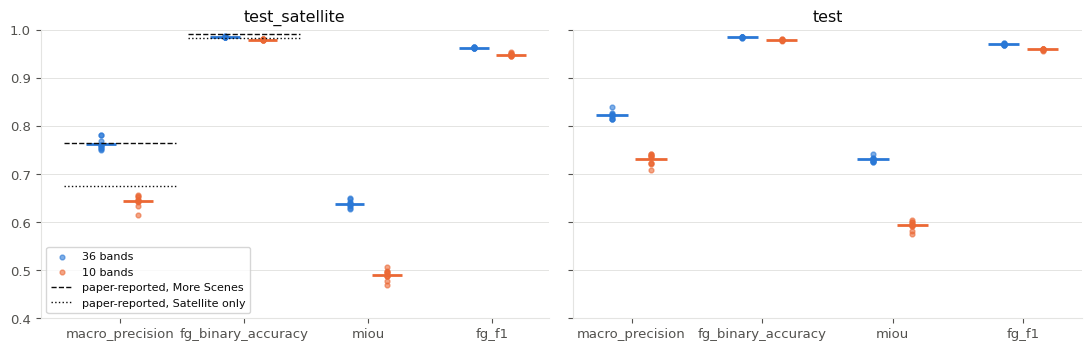

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
shown = ["macro_precision", "fg_binary_accuracy", "miou", "fg_f1"]
x = np.arange(len(shown))

for ax, test in zip(axes, ("test_satellite", "test")):
    for j, (label, df) in enumerate(runs.items()):
        offset = (j - 0.5) * 0.3
        for i, m in enumerate(shown):
            values = df[f"{test}_{m}"]
            ax.scatter(np.full(len(values), i + offset), values, s=12, color=COLOR[label], alpha=0.6,
                       label=label if i == 0 else None)
            ax.hlines(values.mean(), i + offset - 0.12, i + offset + 0.12, color=COLOR[label], lw=2)

    # paper-reported numbers, from the paper's own satellite-only test set
    if test == "test_satellite":
        for name, ls in (("More Scenes", "--"), ("Satellite only", ":")):
            for i, m in enumerate(shown):
                if m in PAPER[name]:
                    ax.hlines(PAPER[name][m], i - 0.45, i + 0.45, color=INK, ls=ls, lw=1,
                              label=f"paper-reported, {name}" if i == 0 else None)
    ax.set(xticks=x, xticklabels=shown, title=test, ylim=(0.4, 1.0))
    ax.grid(axis="y")
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()

Training curves: valid mIoU per epoch for every run; dots mark the epoch each run's test
checkpoint comes from.

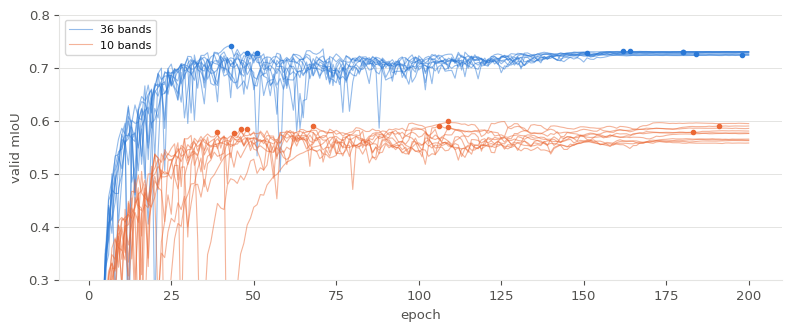

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for label, name in EXPERIMENTS.items():
    for i, (run, best_epoch) in enumerate(zip(runs[label]["run"], runs[label]["best_epoch"])):
        log = pd.read_csv(LOGDIR / name / f"run_{run}" / "_epoch_.csv")
        ax.plot(log["step"], log["valid_miou"], color=COLOR[label], lw=0.8, alpha=0.5,
                label=label if i == 0 else None)
        best = log.set_index("step").loc[best_epoch, "valid_miou"]
        ax.plot(best_epoch, best, "o", color=COLOR[label], ms=3)
ax.set(xlabel="epoch", ylabel="valid mIoU", ylim=(0.3, 0.8))
ax.grid(axis="y"); ax.legend(fontsize=8)
fig.tight_layout()

---
## 2. Direct comparison on the same scenes

The paper's test set no longer exists (its folder was regenerated in June 2026 with different
settings), so the paper-reported numbers come from other scenes. Here every model sees the same
scenes: each experiment's test sets are regenerated from its logged `config.yaml` (same
seeds, same generator settings).

The paper models are 36-band checkpoints, so they run on the 36-band sets only. The `test`
set is also split by scene type, using the `kind` the dataset records for every scene.

In [5]:
def test_sets(config):
    # the experiment's test loaders, regenerated: name -> (cubes, masks, kinds)
    data = HSIDataset(config.data.params)
    sets = {}
    for name in data.loaders[2:]:
        split = data.split(name)
        records = split[(0, range(len(split)))].values()
        sets[name] = tuple(torch.stack([torch.as_tensor(r[k]) for r in records])
                           for k in ("input", "label", "kind"))
    return sets


def subsets(sets):
    # both test sets, plus the mixed one split by scene type
    cubes, masks, kinds = sets["test"]
    out = {"test_satellite": sets["test_satellite"][:2], "test": (cubes, masks)}
    for code, kind in enumerate(SCENE_KINDS):
        out[f"test: {kind}"] = (cubes[kinds == code], masks[kinds == code])
    return out


def no_skill(masks):
    # the better of predicting all background or all one material, per metric
    meter = SegmentationMeter(N_CLASSES, "cpu")
    meter.update(masks, masks)  # only the target counts matter
    return meter.baseline()


def evaluate(model, cubes, masks, batch=500):
    model.eval().to(DEVICE)
    meter = SegmentationMeter(N_CLASSES, "cpu")
    with torch.no_grad():
        for i in range(0, len(cubes), batch):
            meter.update(model(cubes[i:i + batch].to(DEVICE)).argmax(1).cpu(), masks[i:i + batch])
    return meter.compute()

In [6]:
rows, kept = [], {}
for label, name in EXPERIMENTS.items():
    config = OmegaConf.load(LOGDIR / name / "config.yaml")
    sets = test_sets(config)
    data = subsets(sets)

    # our runs: each run's best checkpoint (the one runs.csv reports)
    models = {}
    for run in runs[label]["run"]:
        model = build_model(config)
        model.load_state_dict(torch.load(LOGDIR / name / f"run_{run}" / "model.best.pth", map_location="cpu"))
        models[f"ours, run {run}"] = model

    # the paper models: its released checkpoints, 36 bands
    if config.runtime.n_channels == 36:
        models["paper model, More Scenes"] = SpectralSpatialHSIModel.pretrained("more_scenes")
        models["paper model, Satellite only"] = SpectralSpatialHSIModel.pretrained("satellite_only")

    for model_name, model in models.items():
        for subset, (cubes, masks) in data.items():
            rows.append({"experiment": label, "model": model_name, "subset": subset,
                         **evaluate(model, cubes, masks)})
    for subset, (cubes, masks) in data.items():
        rows.append({"experiment": label, "model": "no-skill", "subset": subset, **no_skill(masks)})
    kept[label] = (sets, models)  # for the examples in section 3

scores = pd.DataFrame(rows)
scores["source"] = scores["model"].str.replace(r", run \d+", "", regex=True)
print(len(scores), "evaluations")

120 evaluations


Check: our runs re-evaluated here should match what the trainer logged (it evaluated in
bf16, this runs in fp32, so tiny differences are expected).

In [7]:
for label in EXPERIMENTS:
    ours = scores[(scores.experiment == label) & (scores.source == "ours")]
    for test in ("test", "test_satellite"):
        here = ours[ours.subset == test].sort_values("model", key=lambda s: s.str.extract(r"(\d+)$")[0].astype(int))
        logged = runs[label].sort_values("run")[f"{test}_macro_precision"].to_numpy()
        print(f"{label:8s} {test:15s} max |here - logged| macro_precision = "
              f"{np.abs(here.macro_precision.to_numpy() - logged).max():.4f}")

36 bands test            max |here - logged| macro_precision = 0.0008
36 bands test_satellite  max |here - logged| macro_precision = 0.0006
10 bands test            max |here - logged| macro_precision = 0.0006
10 bands test_satellite  max |here - logged| macro_precision = 0.0017


Mean over our 10 runs vs the paper models, per test subset. `no-skill` is the floor: per
metric, the better of predicting all background or all the most common material. The
paper-reported rows (two metrics, `test_satellite` only) come from the paper's own test set.

In [8]:
shown = ["macro_precision", "fg_binary_accuracy", "miou", "fg_accuracy", "fg_iou"]
reported = pd.DataFrame([{"experiment": "36 bands", "subset": "test_satellite",
                          "source": f"paper-reported, {name}", **values}
                         for name, values in PAPER.items()])
summary = pd.concat([scores, reported]).groupby(["experiment", "subset", "source"])[shown].mean().round(3)
summary

macro_precision  \
experiment subset          source                                            
10 bands   test            no-skill                                  0.016   
                           ours                                      0.731   
           test: patches   no-skill                                  0.014   
                           ours                                      0.703   
           test: satellite no-skill                                  0.017   
                           ours                                      0.649   
           test: shapes    no-skill                                  0.017   
                           ours                                      0.727   
           test_satellite  no-skill                                  0.017   
                           ours                                      0.643   
36 bands   test            no-skill                                  0.016   
                           ours                                      0.822   
                           paper model, More Scenes                  0.701   
                           paper model, Satellite only               0.414   
           test: patches   no-skill                                  0.014   
                           ours                                      0.810   
                           paper model, More Scenes                  0.703   
                           paper model, Satellite only               0.358   
           test: satellite no-skill                                  0.017   
                           ours                                      0.764   
                           paper model, More Scenes                  0.649   
                           paper model, Satellite only               0.543   
           test: shapes    no-skill                                  0.017   
                           ours                                      0.822   
                           paper model, More Scenes                  0.687   
                           paper model, Satellite only               0.370   
           test_satellite  no-skill                                  0.017   
                           ours                                      0.762   
                           paper model, More Scenes                  0.667   
                           paper model, Satellite only               0.518   
                           paper-reported, More Scenes               0.764   
                           paper-reported, Satellite only            0.676   

                                                           fg_binary_accuracy  \
experiment subset          source                                               
10 bands   test            no-skill                                     0.741   
                           ours                                         0.979   
           test: patches   no-skill                                     0.661   
                           ours                                         0.974   
           test: satellite no-skill                                     0.794   
                           ours                                         0.981   
           test: shapes    no-skill                                     0.786   
                           ours                                         0.984   
           test_satellite  no-skill                                     0.800   
                           ours                                         0.980   
36 bands   test            no-skill                                     0.741   
                           ours                                         0.985   
                           paper model, More Scenes                     0.981   
                           paper model, Satellite only                  0.928   
           test: patches   no-skill                                     0.661   
                           ou

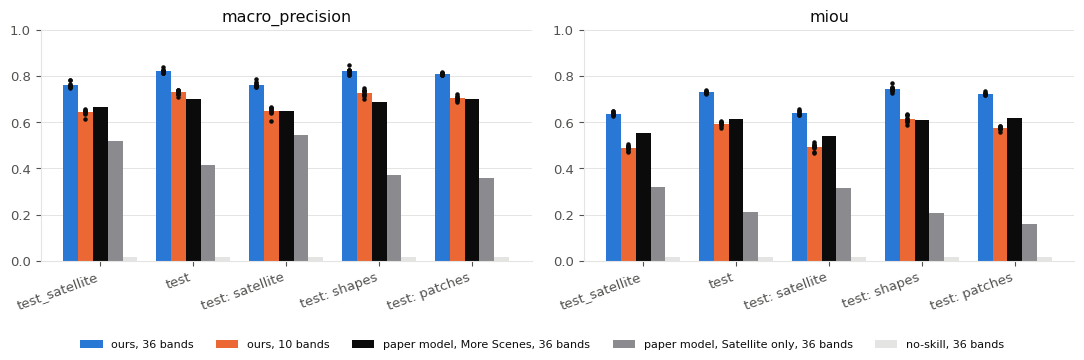

In [9]:
order = ["test_satellite", "test", "test: satellite", "test: shapes", "test: patches"]
sources = {("36 bands", "ours"): S1, ("10 bands", "ours"): S2,
           ("36 bands", "paper model, More Scenes"): INK,
           ("36 bands", "paper model, Satellite only"): MUTED,
           ("36 bands", "no-skill"): GRID}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(order))

for ax, m in zip(axes, ("macro_precision", "miou")):
    for j, ((label, source), color) in enumerate(sources.items()):
        offset = (j - 2) * 0.16
        sel = scores[(scores.experiment == label) & (scores.source == source)]
        means = [sel[sel.subset == s][m].mean() for s in order]
        ax.bar(x + offset, means, 0.16, color=color, label=f"{source}, {label}")
        if source == "ours":  # each run as a dot
            for i, s in enumerate(order):
                values = sel[sel.subset == s][m]
                ax.scatter(np.full(len(values), i + offset), values, s=5, color=INK, zorder=3)
    ax.set(xticks=x, title=m, ylim=(0, 1))
    ax.set_xticklabels(order, rotation=20, ha="right")
    ax.grid(axis="y")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=8, ncol=5, loc="lower center", frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))

---
## 3. Example predictions

Two scenes of each type from the `test` set, predicted by four models: run 0 of each of our
experiments and the two paper models. The 36- and 10-band sets share their masks (same seeds),
so every column is one scene. Colours are material ids, white is background; the number in each
panel is the share of the scene's foreground pixels given the right material.

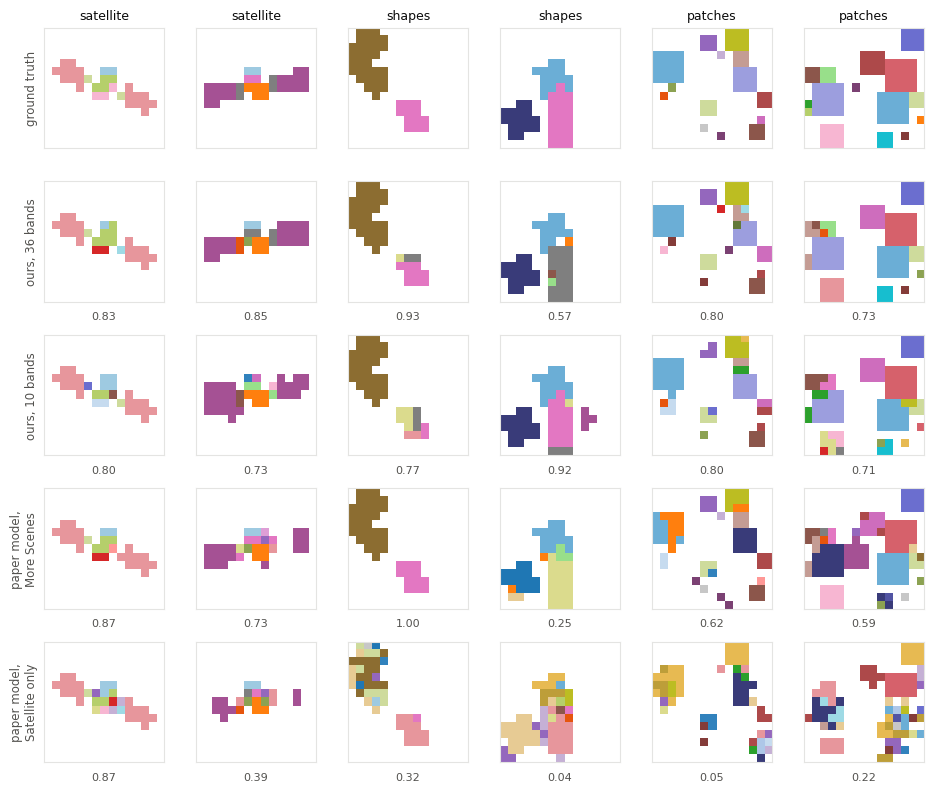

In [10]:
def predict(model, cubes):
    with torch.no_grad():
        return model.eval().to(DEVICE)(cubes.to(DEVICE)).argmax(1).cpu()


(sets36, models36), (sets10, models10) = kept["36 bands"], kept["10 bands"]
cubes36, masks, kinds = sets36["test"]
cubes10, masks10, _ = sets10["test"]
picks = np.concatenate([np.flatnonzero(kinds.numpy() == code)[:2] for code in range(len(SCENE_KINDS))])
assert torch.equal(masks[picks], masks10[picks])

panels = {
    "ground truth": masks[picks],
    "ours, 36 bands": predict(models36["ours, run 0"], cubes36[picks]),
    "ours, 10 bands": predict(models10["ours, run 0"], cubes10[picks]),
    "paper model,\nMore Scenes": predict(models36["paper model, More Scenes"], cubes36[picks]),
    "paper model,\nSatellite only": predict(models36["paper model, Satellite only"], cubes36[picks]),
}

# white background, then 46 distinct material colours
palette = ["white", *plt.cm.tab20.colors, *plt.cm.tab20b.colors, *plt.cm.tab20c.colors]
cmap = ListedColormap(palette[:N_CLASSES])
fig, axes = plt.subplots(len(panels), len(picks), figsize=(1.6 * len(picks), 1.6 * len(panels)))
for r, (name, pred) in enumerate(panels.items()):
    for c, scene in enumerate(picks):
        ax = axes[r, c]
        ax.imshow(pred[c], cmap=cmap, vmin=0, vmax=N_CLASSES - 1, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.spines[["top", "right"]].set_visible(True)  # a full thin frame per scene
        fg = masks[scene] > 0
        if r:  # material accuracy on the scene's foreground
            ax.text(0.5, -0.08, f"{(pred[c][fg] == masks[scene][fg]).float().mean():.2f}",
                    transform=ax.transAxes, ha="center", va="top", fontsize=8, color=INK2)
        if r == 0:
            ax.set_title(SCENE_KINDS[kinds[scene]], fontsize=9)
        if c == 0:
            ax.set_ylabel(name, fontsize=8.5)
fig.tight_layout()